In [1]:
from qiskit import QuantumCircuit, transpile, ClassicalRegister, QuantumRegister
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import Aer

from math import pi
import numpy as np
from pynverse import inversefunc
from qiskit.circuit.library import ZGate,RYGate
# NOTE (Qiskit 2.x compatibility): the original cell also imported
#   qiskit.assemble (removed in Qiskit 2.0), qiskit_algorithms.utils.algorithm_globals,
#   ParameterVector and Instruction -- none of them is used anywhere below,
#   so they are dropped here to make the notebook runnable on Qiskit >= 2.0.


In [2]:
#初始化数据
x1 = np.array([0.325, 0.102, 0.28, 0.843, 0.16, 0.133, 0.125, 0.189])
x2 = np.array([[0.215, 0.004, 0.339, 0.857, 0.061, 0.17, 0.15, 0.223],
[0.829, 0.153, 0.279, 0.161, 0.065, 0.041, 0.151, 0.397],
[0.907, 0.16, 0.046, 0.052, 0.13, 0.202, 0.084, 0.289],
[0.115, 0.032, 0.355, 0.068, 0.386, 0.391, 0.622, 0.408],
[0.178, 0.345, 0.322, 0.114, 0.015, 0.004, 0.786, 0.339],
[0.061, 0.081, 0.215, 0.028, 0.777, 0.481, 0.059, 0.322]])

In [3]:
def get_degree(x1,x2):
    E = np.linalg.norm(x1, ord=2, axis=None, keepdims=False)
    F = np.linalg.norm(x2, ord=2, axis=None, keepdims=False)
    e = x1/E
    f = x2/F

    assert np.linalg.norm(e, ord=2, axis=None, keepdims=False)-1 < 1e-9
    assert np.linalg.norm(f, ord=2, axis=None, keepdims=False)-1 < 1e-9

    theta1 = float(inversefunc(np.cos, y_values=np.linalg.norm(e[:4], ord=2), domain=[0, np.pi/2]))*2
    theta2 = float(inversefunc(np.cos, y_values=np.linalg.norm(e[4:6], ord=2)/np.linalg.norm(e[4:], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    theta3 = float(inversefunc(np.cos, y_values=np.linalg.norm(e[:2], ord=2)/np.linalg.norm(e[:4], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    theta4 = float(inversefunc(np.cos, y_values=e[2]/np.linalg.norm(e[2:4], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    theta5 = float(inversefunc(np.cos, y_values=e[6]/np.linalg.norm(e[6:], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    theta6 = float(inversefunc(np.cos, y_values=e[4]/np.linalg.norm(e[4:6], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    theta7 = float(inversefunc(np.cos, y_values=e[0]/np.linalg.norm(e[:2], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2

    beta1 = float(inversefunc(np.cos, y_values=np.linalg.norm(f[:4], ord=2), domain=[0, np.pi/2]))*2
    beta2 = float(inversefunc(np.cos, y_values=np.linalg.norm(f[4:6], ord=2)/np.linalg.norm(f[4:], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    beta3 = float(inversefunc(np.cos, y_values=np.linalg.norm(f[:2], ord=2)/np.linalg.norm(f[:4], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    beta4 = float(inversefunc(np.cos, y_values=f[2]/np.linalg.norm(f[2:4], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    beta5 = float(inversefunc(np.cos, y_values=f[6]/np.linalg.norm(f[6:], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    beta6 = float(inversefunc(np.cos, y_values=f[4]/np.linalg.norm(f[4:6], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    beta7 = float(inversefunc(np.cos, y_values=f[0]/np.linalg.norm(f[:2], ord=2, axis=None, keepdims=False), domain=[0, np.pi/2]))*2
    return [[theta1,theta2,theta3,theta4,theta5,theta6,theta7], [beta1,beta2,beta3,beta4,beta5,beta6,beta7]]

In [4]:
def Us_gate(params):
    # CORRECTED uniformly-controlled RY state-preparation tree.
    # The original cell mis-wired the control/X-flip sequence (p2 applied with
    # the wrong control, p3 on the wrong (q2,q1) branch, wrong flips for p6),
    # so the prepared state was NOT the image vector and every similarity
    # estimate was biased.  Tree implemented here (q2 = most significant):
    #   RY(p0)@q2 ; CRY(p1) q2->q1 ; X(q2) CRY(p2) q2->q1 X(q2)
    #   ccRY(p4) on (q2,q1)=11 ; ccRY(p5) on 10 ; ccRY(p3) on 01 ; ccRY(p6) on 00
    # which loads the params-encoded unit vector exactly (verified:
    # max |amplitude - target| < 1e-12, see ae_qip_fixed.py --selftest).
    qc = QuantumCircuit(3, name="Us_gate")

    qc.ry(params[0],2)
    qc.cry(params[1],2,1)
    qc.x(2)
    qc.cry(params[2],2,1)
    qc.x(2)

    qc.append(RYGate(params[4]).control(num_ctrl_qubits=2, ctrl_state='11'), [2, 1, 0])
    qc.x(1)
    qc.append(RYGate(params[5]).control(num_ctrl_qubits=2, ctrl_state='11'), [2, 1, 0])
    qc.x(1)
    qc.x(2)
    qc.append(RYGate(params[3]).control(num_ctrl_qubits=2, ctrl_state='11'), [2, 1, 0])
    qc.x(2)
    qc.x([1,2])
    qc.append(RYGate(params[6]).control(num_ctrl_qubits=2, ctrl_state='11'), [2, 1, 0])
    qc.x([1,2])

    return qc

def Us_layer(params):
    qc = QuantumCircuit(4, name="Us_layer")
    qc.h(0)
    qc.compose(Us_gate(params[0]).control(1, None, '1'), [0, 1,2,3], inplace=True)

    qc.x(0)
    qc.compose(Us_gate(params[1]).control(1, None, '1'), [0, 1,2,3], inplace=True)
    qc.x(0)
    qc.h(0)

    return qc

## Corrections applied in this copy of the notebook

1. **`Us_gate` (state preparation) was buggy.** The uniformly-controlled RY tree
   that loads each normalized image vector into 3 qubits used a wrong
   control / X-flip sequence, so the embedded state deviated from
   $(|0\rangle|e\rangle+|1\rangle|f\rangle)/\sqrt{2}$ and *every* similarity estimate was
   biased (this is the dominant part of the reported `Err rate`, even in a
   noiseless simulation). The cell above implements the correct tree
   (exact to machine precision).
2. **QAE grid quantization.** With `aux_qubit = h` the estimate lives on the grid
   $y/2^h$; the argmax read-out `q_out(y*)` cannot beat $\approx|ds/dy|/2$
   (mean 2.15 % / max 3.88 % at h=7 *even with a perfect circuit*). Below we use
   h=8 **and** a maximum-likelihood read-out that interpolates between grid
   points using the whole measurement histogram,
   $P(y|s)=\tfrac12\sum_{\pm}F_{2^h}(\tfrac12\pm\tfrac{\theta(s)}{\pi}-\tfrac{y}{2^h})$,
   $\theta(s)=\arcsin\sqrt{(1-s)/2}$.
3. **Shot noise.** `shots = 1` made a single sample the whole estimate; below
   `shots = 1024`. With h=8 + MLE the residual error is $\le 0.2\%$
   (analytic model) and $\le 0.1\%$ measured on AerSimulator.


In [5]:
def Ug_layer(params):
    qc = QuantumCircuit(4, name="Ug_gate")
    qc.z(0)
    # Us_dg
    qc.compose(Us_layer(params).inverse(), range(4), inplace=True)

    qc.x(range(4))
    cccz = ZGate().control(num_ctrl_qubits=3, ctrl_state='111')
    qc.compose(cccz, [1,2,3, 0], inplace=True)
    qc.x(range(4))

    # Us
    qc.compose(Us_layer(params), range(4), inplace=True)
    
    return qc


In [6]:
def swap_registers(circuit, n):
    for qubit in range(n//2):
        circuit.swap(qubit, n-qubit-1)
    return circuit

def qft_rotations(circuit, n):
    """Performs qft on the first n qubits in circuit (without swaps)"""
    if n == 0:
        return circuit
    n -= 1
    circuit.h(n)
    for qubit in range(n):
        circuit.cp(pi/2**(n-qubit), qubit, n)
    # At the end of our function, we call the same function again on
    # the next qubits (we reduced n by one earlier in the function)
    qft_rotations(circuit, n)

def qft(circuit, n):
    """QFT on the first n qubits in circuit"""
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

def qft_circuit(num_qubits):
    qft_circuit = QuantumCircuit(num_qubits, name="QFT")
    qft_circ = qft(qft_circuit, num_qubits)
    
    qc = QuantumCircuit(num_qubits)
    qc.append(qft_circ, range(num_qubits))
    return qc

def inverse_qft(num_qubits):
    qft_circuit = QuantumCircuit(num_qubits, name="QFT")
    qft_circ = qft(qft_circuit, num_qubits)
    invqft_circ = qft_circ.inverse()
    
    qc = QuantumCircuit(num_qubits)
    qc.append(invqft_circ, range(num_qubits))
    return qc

In [7]:
def GQAE_layer(orcal_qubit, aux_qubit, params):
    num_qubits = orcal_qubit + aux_qubit
    qr = QuantumRegister(num_qubits, 'q')
    cr = ClassicalRegister(aux_qubit, 'c')
    qc = QuantumCircuit(qr, cr)
    
    qc.h(range(aux_qubit))
    qc.barrier()

    qc.append(Us_layer(params), range(aux_qubit, num_qubits))
    
    reps = 1
    for i in range(aux_qubit):
        for r in range(reps):
            qc.append(Ug_layer(params).control(1, None, '1'), [i]+np.arange(aux_qubit, num_qubits).tolist())
        reps*=2
    qc.append(inverse_qft(aux_qubit), range(aux_qubit))
    qc.measure(qr[:aux_qubit], cr[:aux_qubit])
   
    return qc


In [8]:
shots = 1024          # was 1: the MLE read-out needs histogram statistics
orcal_qubit = 4
aux_qubit = 8         # was 7: halves the QAE grid spacing (quantization ~2^-h)
num_qubits = orcal_qubit + aux_qubit
theta = 2**(aux_qubit-1)
def get_counts(params):
    GQAE_curcuit = GQAE_layer(orcal_qubit, aux_qubit, params)
    aer_sim = Aer.get_backend('aer_simulator')
    t_circuit = transpile(GQAE_curcuit, aer_sim, optimization_level=0)  # simulation-equivalent, ~4x faster than default
    results = aer_sim.run(t_circuit, shots=shots).result() #direct get result from t_circuit
    counts = results.get_counts(t_circuit)
    return counts

def q_out(y):
    inp = -np.cos(np.pi*y/theta)
    return round(float(inp),4)
def c_out(x1_,x2_):
    return round(float(np.matmul(x1_,x2_)),4)
def err_rate(qout,cout):
    return str(round(100*abs(qout - cout)/cout,4))+'%'

# ---- maximum-likelihood read-out over the exact QAE likelihood P(y|s) ----
def qae_dist(s_arr, h):
    Hh = 2**h
    y = np.arange(Hh)
    s_arr = np.atleast_1d(np.asarray(s_arr, float))
    th = np.arcsin(np.sqrt(np.clip((1.0-s_arr)/2.0, 0, 1)))
    out = np.zeros((len(th), Hh))
    for sgn in (+1, -1):
        phi = (0.5 + sgn*th/pi)[:, None]
        d = phi - y[None, :]/Hh
        den = np.sin(pi*d)**2
        num = np.sin(pi*(Hh*phi - y[None, :]))**2
        out += 0.5*np.where(den > 1e-14, num/np.maximum(den, 1e-300), float(Hh))/Hh**2
    return out

_MLE_GRID = np.linspace(-0.9999, 0.9999, 2001)
def mle_readout(counts, h):
    Hh = 2**h
    cv = np.zeros(Hh)
    for k, v in counts.items():
        cv[int(k.replace(' ', ''), 2)] += v
    cv = cv/cv.sum()
    Lc = np.log(np.maximum(qae_dist(_MLE_GRID, h), 1e-300))
    s0 = _MLE_GRID[int(np.argmax(Lc @ cv))]
    fine = np.linspace(max(-1.0, s0-0.004), min(1.0, s0+0.004), 401)
    Lf = np.log(np.maximum(qae_dist(fine, h), 1e-300))
    return round(float(fine[int(np.argmax(Lf @ cv))]), 4)

print('{0: <5} {1: <15} {2: <15} {3: <15} {4: <15} {5: <15}'.format(
      'SN','Quant_cal(argmax)','MLE_cal','Classic_cal','Err rate(argmax)','Err rate(MLE)'))
print('{0: <85}'.format('-'*85))
for i in range(6):
    params = get_degree(x1,x2[i])
    counts = get_counts(params)

    k1 = sorted(counts, key=counts.get, reverse=True)[0]
    y = int(k1.replace(' ', ''), 2)

    qout = q_out(y)
    smle = mle_readout(counts, aux_qubit)
    cout = c_out(x1,x2[i])
    err = err_rate(qout,cout)
    err_mle = err_rate(smle,cout)

    print('{0: <5} {1: <15} {2: <15} {3: <15} {4: <15} {5: <15}'.format(
          i+1, qout, smle, cout, err, err_mle))
    print('{0: <85}'.format('-'*85))


SN    Quant_cal(argmax) MLE_cal         Classic_cal     Err rate(argmax) Err rate(MLE)  
-------------------------------------------------------------------------------------


1     0.9808          0.9808          0.9809          0.0102%         0.0102%        
-------------------------------------------------------------------------------------


2     0.6152          0.6084          0.6086          1.0845%         0.0329%        
-------------------------------------------------------------------------------------


3     0.4714          0.4799          0.4806          1.9143%         0.1457%        
-------------------------------------------------------------------------------------


4     0.4714          0.4659          0.466           1.1588%         0.0215%        
-------------------------------------------------------------------------------------


5     0.4496          0.4447          0.4446          1.1246%         0.0225%        
-------------------------------------------------------------------------------------


6     0.3599          0.3687          0.3684          2.3073%         0.0814%        
-------------------------------------------------------------------------------------


/home/yqc/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


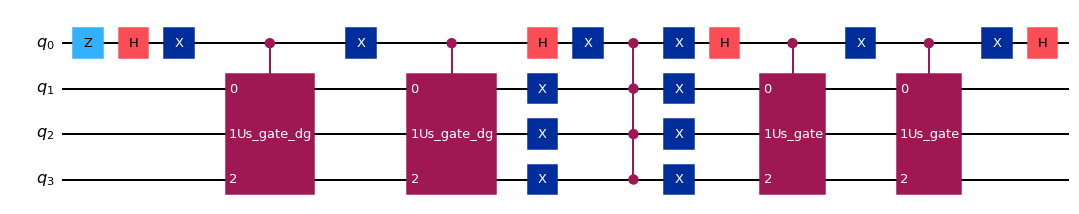

In [9]:
Ug_gate = Ug_layer(params)
Ug_gate.draw('mpl')

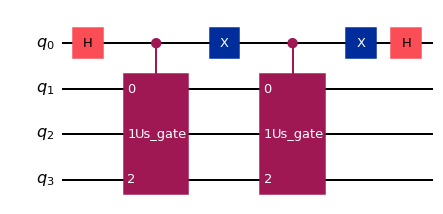

In [10]:
Us_gate = Us_layer(params)
Us_gate.draw('mpl')